In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

### **Data Import, Setup & Data Cleaning**

Import CSV using Pandas

In [5]:
url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/refs/heads/main/social_media_engagement_5000.csv"
file = pd.read_csv(url)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
print("Social Media Engagement Row Data:")
file

Social Media Engagement Row Data:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
5,92386,16.0,Other,Canada,174310,video,tech,12535.0,1790.0,99.0,1427,24893,16-09-2023,684761,False,desktop,positive,#fitness,0.579440
6,47194,25.0,Male,Japan,481598,video,travel,11703.0,2276.0,1465.0,6287,96327,15-04-2022,519759,True,tablet,negative,#music,0.160329
7,97498,57.0,Female,Canada,343415,image,travel,9611.0,146.0,424.0,1699,68446,20-12-2023,698739,False,desktop,neutral,#travel #music #fitness,0.148745
8,54131,54.0,Female,UK,907449,image,fashion,NaN,2379.0,1897.0,5650,36283,06-07-2023,615809,True,desktop,negative,#music #fun #fitness,0.533914
9,70263,62.0,Female,Australia,495037,video,lifestyle,14106.0,2480.0,1053.0,3969,87972,16-11-2022,452146,False,tablet,neutral,#lifestyle #love,0.200507


Check/convert data types,Detect missing values (isnull(), isna()) and Convert date columns to datetime

In [6]:
def load_and_structure_data():
    try:
        url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/refs/heads/main/social_media_engagement_5000.csv"
        file = pd.read_csv(url)

        print("Initial Data:")
        file.info()
        file['posted_at'] = pd.to_datetime(file['posted_at'], format='%d-%m-%Y', errors='coerce')

        for col in file.columns:
            if "date" in col.lower():
                file[col] = pd.to_datetime(file[col], format='%d-%m-%Y', errors='coerce')
                file[col] = file[col].fillna(file[col].ffill())

        for col in file.columns:
            if file[col].dtype == 'bool':
                file[col] = file[col].fillna(file[col].mode()[0])

        for i in file.select_dtypes(include=['bool', 'object']).columns:
            file[i] = file[i].astype(str).str.strip().str.title()

        for col in file.columns:
            if pd.api.types.is_numeric_dtype(file[col]):
                if file[col].isnull().any():
                    if col in ['likes', 'comments', 'shares']:
                        if 'hashtags' in file.columns:
                            file[col] = file.groupby('hashtags')[col].transform(lambda x: x.fillna(x.median() if not x.dropna().empty else file[col].median()))
                        else:
                            file[col] = file[col].fillna(file[col].median())
                    else:
                        file[col] = file[col].fillna(file[col].median())
            else:
                file[col] = file[col].fillna("Unknown")

        file = file.sort_values(by=file.columns[0]).reset_index(drop=True)
        file['gender'] = file['gender'].replace("Nan", "Unknown")
        print("Unique gender values after correction:")
        print(file['gender'].unique())
        print("Shape:", file.shape)
        print("\nColumn Names:")
        print(file.columns)
        print("\nCleaned Data Types:")
        print(file.dtypes)
        print("\nMissing Values:")
        print(file.isnull().sum())
        print("\nCleaned Data info:")
        file.info()
        return file
    except FileNotFoundError:
        print(f"Error: File '{url}' not found.")
    except pd.errors.EmptyDataError:
        print("Error: The file is empty.")
    except Exception as e:
        print(f"Unexpected error: {e}")
print(load_and_structure_data())


Streaming output truncated to the last 5000 lines.
0                   #Love #Fashion         0.033261  
1        #Travel #Fitness #Fashion         0.091057  
2               #Tech #Reels #Love         0.232401  
3                    #Travel #Tech         0.639777  
4                       #Fun #Love         0.594699  
5                           #Music         0.295710  
6                         #Fitness         0.147728  
7        #Fashion #Tech #Lifestyle         0.049215  
8                 #Lifestyle #Love         0.303592  
9                      #Tech #Love         0.303964  
10         #Reels #Tech #Lifestyle         0.137506  
11                        #Fashion         0.054539  
12                      #Fun #Tech         0.114794  
13                   #Fashion #Fun         0.106896  
14     #Foodie #Fashion #Lifestyle         0.380579  
15                    #Reels #Tech         0.074176  
16             #Fun #Music #Travel         0.235290  
17           #Reels #Tech #Fitn

Use NumPy arrays for basic array operations

In [7]:
age_arr = file["age"].to_numpy()
impression_count_arr = file["impression_count"].to_numpy()
post_id_arr = file["post_id"].to_numpy()
likes_arr = file["likes"].to_numpy()
comments_arr = file["comments"].to_numpy()
shares_arr = file["shares"].to_numpy()
watch_time_sec_arr = file["watch_time_sec"].to_numpy()
follower_count_arr = file["follower_count"].to_numpy()
engagement_rate_arr = file["engagement_rate"].to_numpy()
mean_age = np.mean(age_arr)
median_age = np.median(age_arr)
min_age = np.min(age_arr)
max_age = np.max(age_arr)
std_age = np.std(age_arr)
print("Mean age:", mean_age)
print("Median age:", median_age)
print("Minimum age:", min_age)
print("Maximum age:", max_age)
print("Standard deviation:", std_age)
print("Posts with more than 100 likes:",likes_arr[likes_arr > 100])
print("Posts with more than 50 comments",comments_arr[comments_arr > 50])
print("Maximum likes",np.max(likes_arr))

Mean age: nan
Median age: nan
Minimum age: nan
Maximum age: nan
Standard deviation: nan
Posts with more than 100 likes: [ 7011. 11750.  4862. ... 13487. 16894. 14830.]
Posts with more than 50 comments [ 354. 2606.  344. ... 2734. 1289.  503.]
Maximum likes nan


**● Duplicate Handling**
Identify & remove duplicates

In [8]:
file = file.drop_duplicates()
initial_rows = len(file)
print(f"Removed {initial_rows - len(file)} duplicate rows.")
print("Duplicates:",file.duplicated().sum())

Removed 0 duplicate rows.
Duplicates: 0


**● Data Formatting**
■ Fix incorrect data types

In [11]:
for col in ["age", "likes", "comments", "shares"]:
  if col in file.columns:
    file[col] = pd.to_numeric(file[col], errors='coerce').astype('Int64')
print("\nCleaned Data Types:")
print(file.dtypes)


Cleaned Data Types:
user_id               int64
age                   Int64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes                 Int64
comments              Int64
shares                Int64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object


■ Standardize categories (e.g., gender labels)

In [12]:
for col in file.select_dtypes(include=['bool','object']).columns:
    file[col] = file[col].astype(str).str.strip().str.title()
string_columns = file.select_dtypes(include=['object']).columns
print(string_columns.tolist())

['gender', 'country', 'post_type', 'post_category', 'posted_at', 'is_verified', 'device_type', 'sentiment', 'hashtags']


■ Correct unrealistic values in likes, comments, shares

In [14]:
cols = ['likes', 'comments', 'shares']
print(file[cols].describe())
print(file[cols].lt(0).sum())
file[cols] = file[cols].mask(file[cols] < 0, 0)
for col in ['likes', 'comments', 'shares']:
    file.loc[file[col] > 1000000, col] = 0

             likes    comments      shares
count       5000.0      5000.0      5000.0
mean     9803.8324   1457.1298    972.5506
std    5957.295788  893.917601  595.929688
min            0.0         0.0         0.0
25%        4625.75       675.0      447.75
50%         9776.0      1454.5       981.5
75%        14959.0     2235.25      1483.0
max        19998.0      2999.0      1999.0
likes       0
comments    0
shares      0
dtype: Int64


**● Feature Cleaning**
■ Extract hashtag count


In [15]:
print("Hashtag Count:",file['hashtags'].str.count('#').sum())

Hashtag Count: 9993


■ Clean sentiment labels

In [16]:
file["sentiment"] = file["sentiment"].str.strip().str.lower()
file["sentiment"]

,sentiment
0,negative
1,negative
2,positive
3,negative
4,negative
5,positive
6,negative
7,neutral
8,negative
9,neutral


### **Data Exploration using Pandas**

● View dataset structure using head(), tail(), shape, and columns.

In [17]:
file.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,17-12-2022,81734,False,Mobile,negative,#Foodie #Travel #Love,0.190862
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,02-06-2023,5963,False,Mobile,negative,#Fitness,0.201493
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,6946,44858,07-05-2023,501783,False,Tablet,positive,#Foodie,0.137345
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,12-02-2023,480212,False,Mobile,negative,#Music #Foodie #Fun,0.106195
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,4798,6019,23-05-2023,383936,False,Mobile,negative,#Travel,2.777372


In [18]:
file.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,25-06-2022,646147,False,Mobile,positive,#Travel #Fun,0.466761
4996,22100,38,Other,Uae,677076,Reel,Education,16924,2734,1583,7764,34196,18-11-2022,584603,False,Desktop,negative,#Foodie #Reels,0.621155
4997,67021,63,Female,Usa,273595,Text,Travel,13487,0,167,7466,23680,06-04-2023,483550,False,Desktop,positive,#Lifestyle #Tech,0.679688
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,16-05-2022,183295,False,Tablet,positive,#Reels #Love #Fitness,0.223518
4999,73400,54,Other,Japan,712252,Text,Travel,14830,503,1798,3743,14234,04-03-2023,585760,False,Desktop,neutral,#Foodie #Lifestyle #Fashion,1.203527


In [19]:
file.shape

(5000, 19)

In [20]:
file.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

● Check data types and info with info() and dtypes.

In [21]:
file.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   Int64  
 2   gender            5000 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             5000 non-null   Int64  
 8   comments          5000 non-null   Int64  
 9   shares            5000 non-null   Int64  
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   object 
 15  device_type       5000 non-null   object 
 16  sentiment         5000 non-null   object 


● Generate summary statistics using describe()

In [22]:
file.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
count,5000.000000,4850.0,5000.000000,5000.0,5000.0,5000.0,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.454021,548042.909000,9803.8324,1457.1298,972.5506,4014.503200,50013.732800,393698.224800,0.964356
std,26090.370121,14.912381,260646.957267,5957.295788,893.917601,595.929688,2308.096459,28844.939104,230927.884535,5.318029
min,10055.000000,13.0,100068.000000,0.0,0.0,0.0,0.000000,105.000000,87.000000,0.006363
25%,32309.500000,26.0,322543.500000,4625.75,675.0,447.75,2017.750000,24988.250000,194480.000000,0.145781
50%,54374.500000,38.0,548077.500000,9776.0,1454.5,981.5,4034.500000,49934.500000,388982.000000,0.253896
75%,77180.500000,51.0,771574.500000,14959.0,2235.25,1483.0,6020.250000,74662.250000,589744.250000,0.504794
max,99963.000000,64.0,999455.000000,19998.0,2999.0,1999.0,7998.000000,99995.000000,799533.000000,191.504348


● Analyze categorical distributions using value_counts(), unique(), and
nunique().

In [23]:
file['post_category'].value_counts()

,count
post_category,
Fitness,675
Tech,665
Music,635
Education,631
Lifestyle,607
Travel,600
Fashion,594
Food,593


In [24]:
file['post_category'].unique()

array(['Fitness', 'Food', 'Tech', 'Travel', 'Fashion', 'Lifestyle',
       'Education', 'Music'], dtype=object)

In [25]:
file['post_category'].nunique()

8

● Create a correlation matrix for numeric fields.

In [26]:
corr_matrix = file.select_dtypes(include=[np.number]).corr()
print("\nCorrelation Matrix:")
display(corr_matrix)


Correlation Matrix:


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
user_id,1.000000,-0.006789,0.020051,0.021377,-0.037686,0.015422,-0.016847,0.015326,0.010124,-0.004282
age,-0.006789,1.000000,-0.013353,-0.040013,-0.006960,0.012803,0.005677,0.013513,-0.025416,0.008044
post_id,0.020051,-0.013353,1.000000,0.010650,-0.009489,0.004496,0.018374,-0.007709,-0.002844,0.010139
likes,0.021377,-0.040013,0.010650,1.000000,-0.017593,0.001008,0.002865,0.002746,-0.023670,0.094458
comments,-0.037686,-0.006960,-0.009489,-0.017593,1.000000,0.006953,-0.017009,-0.009809,-0.008651,0.001464
shares,0.015422,0.012803,0.004496,0.001008,0.006953,1.000000,0.015372,0.006399,-0.005979,0.021305
watch_time_sec,-0.016847,0.005677,0.018374,0.002865,-0.017009,0.015372,1.000000,-0.004335,0.002761,-0.001148
impression_count,0.015326,0.013513,-0.007709,0.002746,-0.009809,0.006399,-0.004335,1.000000,-0.015513,-0.232226
follower_count,0.010124,-0.025416,-0.002844,-0.023670,-0.008651,-0.005979,0.002761,-0.015513,1.000000,0.002292
engagement_rate,-0.004282,0.008044,0.010139,0.094458,0.001464,0.021305,-0.001148,-0.232226,0.002292,1.000000


● Use groupby() to summarize metrics (e.g., avg likes by post type, impressions
by country).

In [27]:
print("\nAverage Likes by Post Type:")
display(file.groupby("post_type")["likes"].mean())


Average Likes by Post Type:


,likes
post_type,
Image,9845.542101
Reel,9683.361652
Text,9783.590361
Video,9908.120816


In [28]:
print("\nTotal Impressions by Country:")
display(file.groupby("country")["impression_count"].sum())


Total Impressions by Country:


,impression_count
country,
Australia,23834767
Brazil,24793360
Canada,24984716
France,25656926
Germany,23816649
India,28067377
Japan,23418816
Uae,24610992
Uk,25201861


### **Data Wrangling**

● Use merge, concat, or join if combining DataFrames.

In [29]:
file1 = file.iloc[:2500]
file2 = file.iloc[2500:]
combined_file = pd.concat([file1, file2], ignore_index=True)
print(combined_file.shape)

(5000, 19)


In [30]:
engagement_cols = ['likes', 'comments', 'shares']
file1 = file.drop(columns=engagement_cols)
file2 = file[engagement_cols]
combined_file = pd.concat([file1, file2], axis=1)
print(combined_file.head())

   user_id  age  gender country  post_id post_type post_category  \
0    25795   43  Female  Brazil   496713     Image       Fitness   
1    10860   33    Male  Brazil   157326      Reel          Food   
2    86820   32  Female      Uk   109864      Text          Food   
3    64886   51   Other  France   848877      Text       Fitness   
4    16265   34   Other      Uk   449706     Image       Fitness   

   watch_time_sec  impression_count   posted_at  follower_count is_verified  \
0            5726             44650  17-12-2022           81734       False   
1            5947             80216  02-06-2023            5963       False   
2            6946             44858  07-05-2023          501783       False   
3             229             70455  12-02-2023          480212       False   
4            4798              6019  23-05-2023          383936       False   

  device_type sentiment               hashtags  engagement_rate  likes  \
0      Mobile  negative  #Foodie #Travel #

In [31]:
file1 = file[['likes', 'comments', 'shares']].copy()
file1['Post_ID'] = range(1, len(file1) + 1)
file2 = file[['likes', 'comments']].copy()
file2['Post_ID'] = range(1, len(file2) + 1)
merged_file = pd.merge(file1,file2,on='Post_ID',how='inner',suffixes=('_file1', '_file2'))
print(merged_file.head())

   likes_file1  comments_file1  shares  Post_ID  likes_file2  comments_file2
0         7011             354    1157        1         7011             354
1        11750            2606    1807        2        11750            2606
2         4862             344     955        3         4862             344
3         5350            1083    1049        4         5350            1083
4        12682            2735    1300        5        12682            2735


In [32]:
file1 = file[['likes', 'comments']].copy()
file2 = file[['shares']].copy()
joined_file = file1.join(file2, lsuffix='_left', rsuffix='_right')
print(joined_file.head())

   likes  comments  shares
0   7011       354    1157
1  11750      2606    1807
2   4862       344     955
3   5350      1083    1049
4  12682      2735    1300


● Create new fields such as engagement_score, log-transformed metrics
(optional), and hashtag_count.

In [33]:
file['engagement_score'] = (
    file['likes'] + file['comments'] + file['shares']
)

print(file[['likes', 'comments', 'shares', 'engagement_score']].head())

   likes  comments  shares  engagement_score
0   7011       354    1157              8522
1  11750      2606    1807             16163
2   4862       344     955              6161
3   5350      1083    1049              7482
4  12682      2735    1300             16717


In [34]:
file['log_likes'] = np.log1p(file['likes'])

file['log_comments'] = np.log1p(file['comments'])

file['log_shares'] = np.log1p(file['shares'])
print(file[['likes', 'log_likes',
          'comments', 'log_comments',
          'shares', 'log_shares']].head())

   likes  log_likes  comments  log_comments  shares  log_shares
0   7011   8.855378       354      5.872118    1157     7.05445
1  11750   9.371694      2606      7.865955    1807    7.499977
2   4862   8.489411       344      5.843544     955    6.862758
3   5350   8.585039      1083      6.988413    1049    6.956545
4  12682   9.448018      2735      7.914252    1300    7.170888


In [35]:
file['hashtag_count'] = (
    file['hashtags']
    .fillna('')
    .str.count(r'#\w+')
)

print(file[['hashtags', 'hashtag_count']].head())

                hashtags  hashtag_count
0  #Foodie #Travel #Love              3
1               #Fitness              1
2                #Foodie              1
3    #Music #Foodie #Fun              3
4                #Travel              1


In [36]:
top_posts = file.sort_values(
    by='engagement_score',
    ascending=False
).head(10)

print(top_posts)

      user_id  age  gender country  post_id post_type post_category  likes  \
41      90038   29     Nan      Uk   147547     Video          Food  19918   
1632    36660   36    Male  Brazil   641620     Image          Food  19986   
3814    90360   43  Female     Uae   943395     Video          Food  19920   
3223    92909   19    Male   India   182790     Video          Food  19871   
2998    65267   14     Nan  Canada   462928      Reel         Music  19877   
1605    52534   52  Female     Usa   716963      Text       Fashion  19981   
3741    81354   60    Male  Canada   422233     Video     Lifestyle  19877   
2198    78011   25  Female     Usa   647678      Reel          Tech  19884   
4495    71744   51    Male  France   160384      Text          Tech  19713   
1164    85520   49    Male     Uae   594285     Video     Education  19560   

      comments  shares  watch_time_sec  impression_count   posted_at  \
41        2859    1903            3043             73974  18-01-2023 

● Perform groupby summaries by post_type, country, and sentiment.

In [37]:
post_summary = file.groupby('post_type').agg(
    total_likes=('likes', 'sum'),
    average_likes=('likes', 'mean'),
    total_comments=('comments', 'sum'),
    average_comments=('comments', 'mean'),
    total_shares=('shares', 'sum'),
    average_shares=('shares', 'mean'),
    post_count=('post_type', 'count')
).reset_index()

print(post_summary)

  post_type  total_likes  average_likes  total_comments  average_comments  \
0     Image     12277391    9845.542101         1845083       1479.617482   
1      Reel     12423753    9683.361652         1866998       1455.181606   
2      Text     12180570    9783.590361         1810998       1454.616867   
3     Video     12137448    9908.120816         1762570       1438.832653   

   total_shares  average_shares  post_count  
0       1234622      990.073777        1247  
1       1220492      951.279813        1283  
2       1223961      983.101205        1245  
3       1183678      966.267755        1225  


In [38]:
country_summary = file.groupby('country').agg(
    total_likes=('likes', 'sum'),
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    post_count=('country', 'count')
).reset_index()

print(country_summary)

     country  total_likes  average_likes  average_comments  average_shares  \
0  Australia      4903210    9945.659229       1455.438134     1000.955375   
1     Brazil      4871731    9666.132937       1457.761905      982.755952   
2     Canada      5041087    9826.680312       1511.565302      960.736842   
3     France      5013575   10108.014113       1436.441532     1023.247984   
4    Germany      4731498    9656.118367        1501.27551      917.616327   
5      India      5077283    9490.248598       1461.340187     1012.616822   
6      Japan      4660888    9874.762712       1476.516949      933.622881   
7        Uae      5002949    9946.220676       1472.763419      968.956262   
8         Uk      4766904    9669.176471        1420.53144       950.78499   
9        Usa      4950037    9880.313373       1377.281437      968.882236   

   post_count  
0         493  
1         504  
2         513  
3         496  
4         490  
5         535  
6         472  
7         503

In [39]:
sentiment_summary = file.groupby('sentiment').agg(
    total_likes=('likes', 'sum'),
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    post_count=('sentiment', 'count')
).reset_index()

print(sentiment_summary)

  sentiment  total_likes  average_likes  average_comments  average_shares  \
0       nan      1541256       10275.04       1403.166667     1048.846667   
1  negative      9496608         9892.3       1478.669792      982.007292   
2   neutral     14708076    9632.007859       1488.209561      970.055665   
3  positive     23273222    9849.014812       1431.720271      965.477782   

   post_count  
0         150  
1         960  
2        1527  
3        2363  


In [40]:
sentiment_summary = sentiment_summary.sort_values(
    by='average_likes',
    ascending=False
)

print("Average Likes",sentiment_summary)

Average Likes   sentiment  total_likes  average_likes  average_comments  average_shares  \
0       nan      1541256       10275.04       1403.166667     1048.846667   
1  negative      9496608         9892.3       1478.669792      982.007292   
3  positive     23273222    9849.014812       1431.720271      965.477782   
2   neutral     14708076    9632.007859       1488.209561      970.055665   

   post_count  
0         150  
1         960  
3        2363  
2        1527  


### ** Statistical Analysis**

Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate,
followers:
● Mean, median, mode
● Standard deviation, variance
● Percentiles
● (Optional) Skewness and kurtosis

In [41]:
stats_metrics = [
    c
    for c in [
        "likes",
        "comments",
        "shares",
        "watch_time",
        "engagement_rate",
        "followers",
    ]
    if c in file.columns
]

if stats_metrics:
  stats_summary = pd.DataFrame(index=stats_metrics)
  stats_summary["Mean"] = file[stats_metrics].mean()
  stats_summary["Median"] = file[stats_metrics].median()
  stats_summary["Mode"] = file[stats_metrics].mode().iloc[
      0
  ]
  stats_summary["Std Dev"] = file[stats_metrics].std()
  stats_summary["Variance"] = file[stats_metrics].var()
  stats_summary["25th Percentile"] = file[stats_metrics].quantile(0.25)
  stats_summary["50th Percentile (Median)"] = file[stats_metrics].quantile(0.50)
  stats_summary["75th Percentile"] = file[stats_metrics].quantile(0.75)
  stats_summary["Skewness"] = file[stats_metrics].skew()
  stats_summary["Kurtosis"] = file[stats_metrics].kurtosis()

  print("Comprehensive Statistical Summary:")
  display(stats_summary)

Comprehensive Statistical Summary:


,Mean,Median,Mode,Std Dev,Variance,25th Percentile,50th Percentile (Median),75th Percentile,Skewness,Kurtosis
likes,9803.8324,9776.0,0.0,5957.295788,35489373.108132,4625.75,9776.0,14959.0,0.000228,-1.213896
comments,1457.1298,1454.5,0.0,893.917601,799088.677487,675.0,1454.5,2235.25,0.011841,-1.21047
shares,972.5506,981.5,0.0,595.929688,355132.192678,447.75,981.5,1483.0,-0.002932,-1.215102
engagement_rate,0.964356,0.253896,0.006363,5.318029,28.281435,0.145781,0.253896,0.504794,18.781271,482.991739


## **Data Visualization**

In [ ]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 20))

**MATPLOTLIB PLOTS**

**1. Scatter Plot: likes vs impressions**

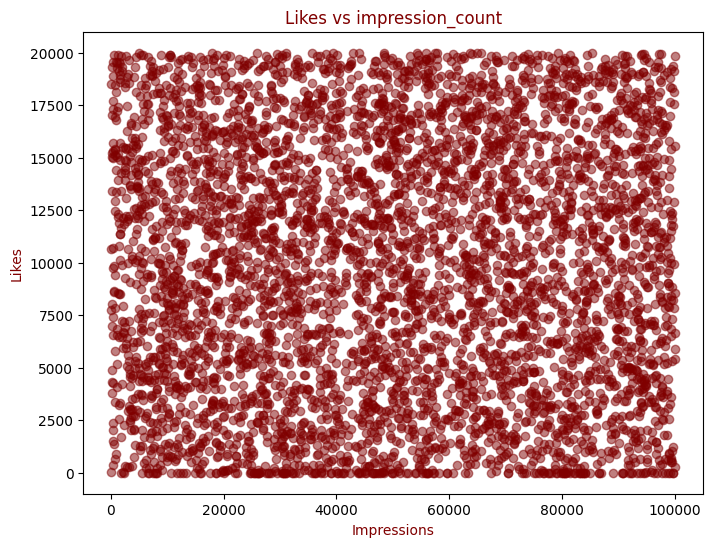

In [42]:
plt.figure(figsize=(8,6))
plt.scatter(file["impression_count"], file["likes"], alpha=0.5, color="Maroon")
plt.title("Likes vs impression_count", color="Maroon")
plt.xlabel("Impressions", color="Maroon")
plt.ylabel("Likes", color="Maroon")
plt.show()

**Likes vs Impressions Insight**:Likes vary widely across impression counts; no clear, strong linear relationship is visible.

**2. Line: Daily Engagement Trend**

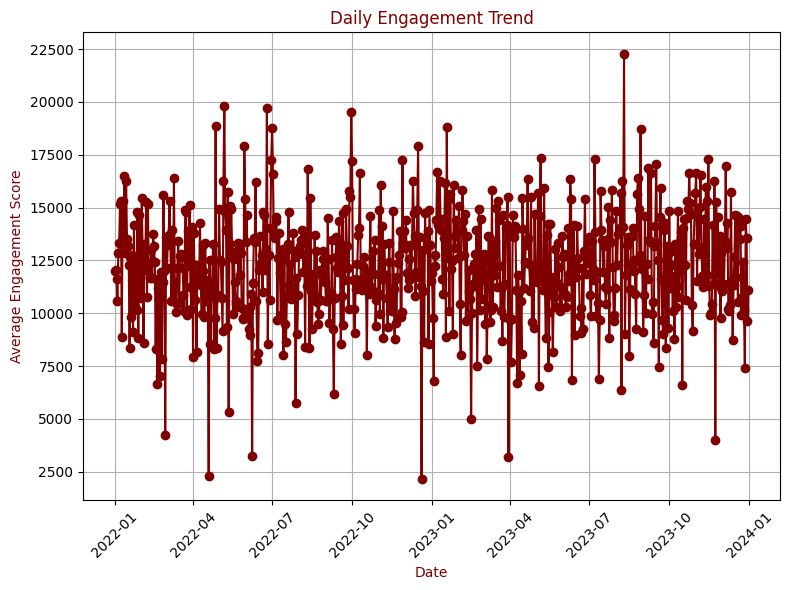

In [59]:
plt.figure(figsize=(8,6))
file["posted_at"] = pd.to_datetime(file["posted_at"],format='%d-%m-%Y')

daily = file.groupby(file["posted_at"].dt.date)["engagement_score"].mean()

plt.plot(daily.index, daily.values, marker="o", color="Maroon")

plt.xlabel("Date", color="Maroon")
plt.ylabel("Average Engagement Score",color="Maroon")
plt.title("Daily Engagement Trend", color="Maroon")
plt.grid(True)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**Daily Engagement Trend Insight**:Daily engagement fluctuates, without an obvious sustained upward or downward trend.

**3. Bar: Posts by Category**

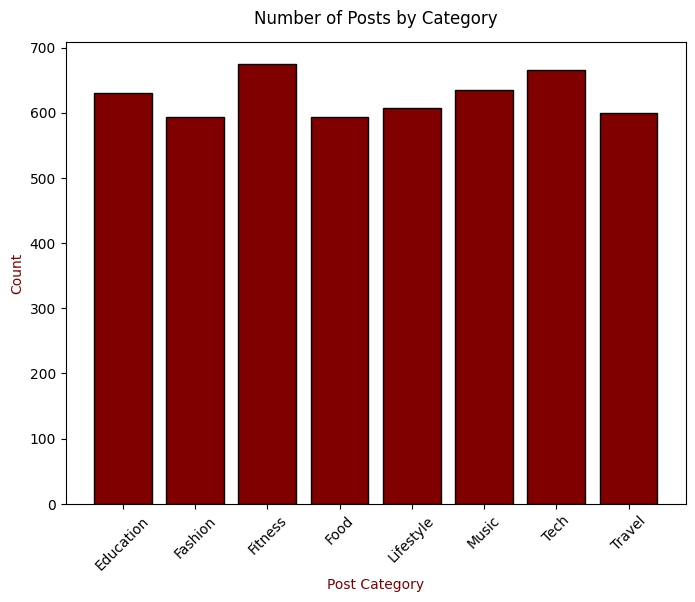

In [43]:
plt.figure(figsize=(8,6))
post_count = file.groupby('post_category')['likes'].count()
plt.bar(post_count.index, post_count.values, color='Maroon', edgecolor='black')
plt.title('Number of Posts by Category', fontsize=12, pad=13)
plt.xlabel('Post Category', fontsize=10,color='Maroon')
plt.ylabel('Count', fontsize=10,color='Maroon')
plt.xticks(rotation=45)
plt.show()

**Posts by Category Insight**:
Post counts are relatively balanced across categories.

**4. Pie: Gender Distribution**

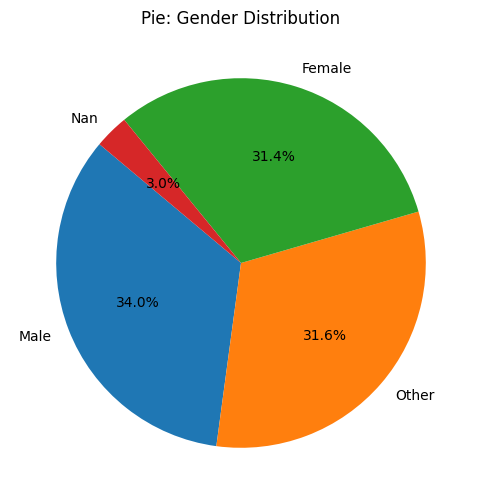

In [47]:
plt.figure(figsize=(6,6))
gender_counts = file["gender"].value_counts()
plt.pie(gender_counts,labels=gender_counts.index,autopct="%1.1f%%",startangle=140,)
plt.title("Pie: Gender Distribution")
plt.show()

**Gender Distribution Insight**:
Male, Female, and Other categories each account for approximately one-third of the records.

**5. Histogram: Age**

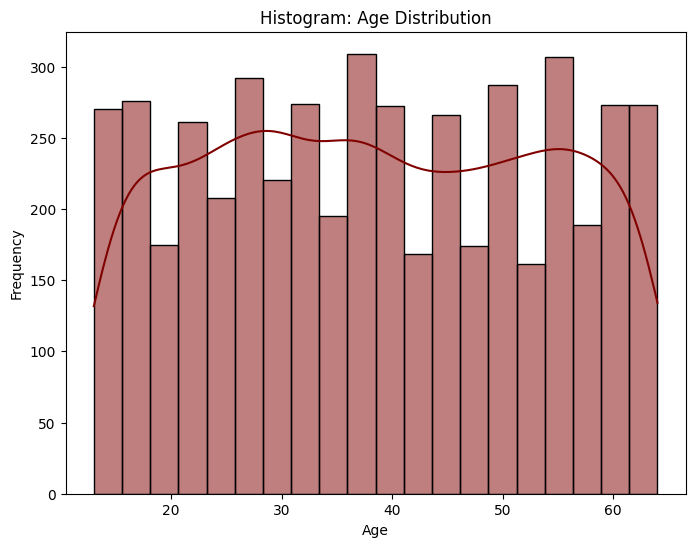

In [58]:
plt.figure(figsize=(8,6))
if "age" in file.columns:
  sns.histplot(file["age"], bins=20, kde=True, color="Maroon")
  plt.title("Histogram: Age Distribution")
  plt.xlabel("Age")
  plt.ylabel("Frequency")

**Age Distribution Insight**: Ages cover a broad range, with a visible peak around the late-thirties range.

**6. Boxplot: Engagement Rate**

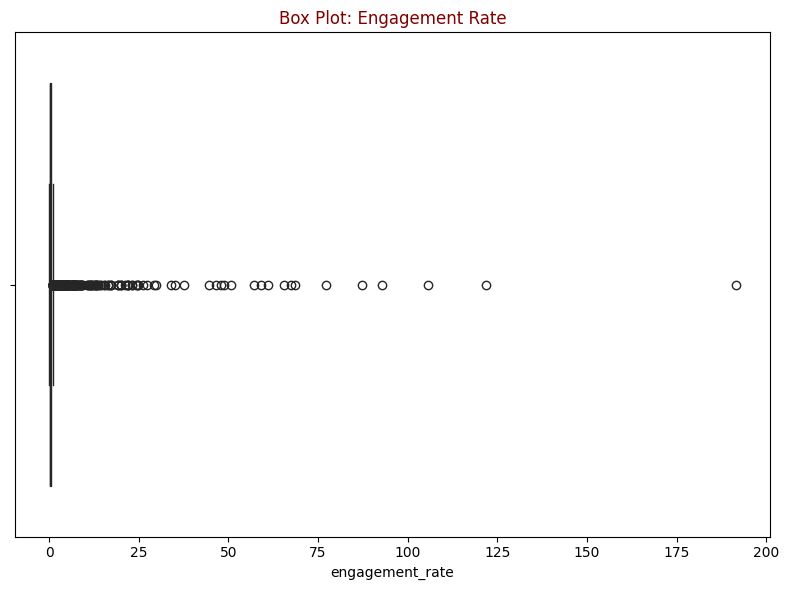

In [48]:
plt.figure(figsize=(8,6))
if "engagement_rate" in file.columns:
  sns.boxplot(x=file["engagement_rate"],color='Maroon')
  plt.title("Box Plot: Engagement Rate",color='Maroon')

plt.tight_layout()
plt.show()

**Engagement Rate Insight**: Engagement rates are right-skewed, with several high-value outliers.

**SEABORN PLOTS**

**7. Count Plot: Post Type**

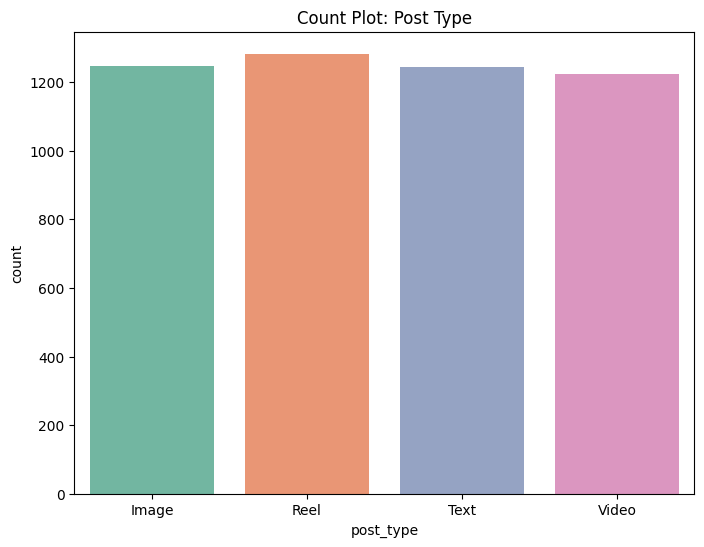

In [49]:
if "post_type" in file.columns:
  plt.figure(figsize=(8,6))
  sns.countplot(data=file, x="post_type", hue="post_type", palette="Set2", legend=False)
  plt.title("Count Plot: Post Type")
  plt.show()

**Post Type Insight**: Reel, Video, Text, and Image posts have broadly similar counts.

**8. Bar Plot: Average Likes by Category**

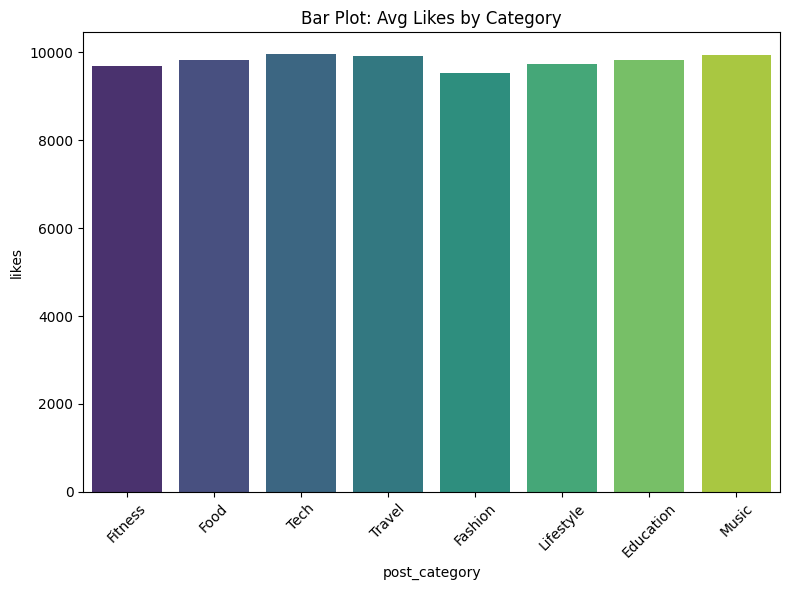

In [46]:
if "post_category" in file.columns and "likes" in file.columns:
  plt.figure(figsize=(8, 6))
  sns.barplot(data=file, x="post_category", y="likes", errorbar=None, hue="post_category", palette="viridis", legend=False)
  plt.title("Bar Plot: Avg Likes by Category")
  plt.xticks(rotation=45)
  plt.tight_layout()
  plt.show()

**Average Likes by Category Insight**: Average likes are relatively similar across categories, with modest differences.

**9. Violin: Followers vs Sentiment**

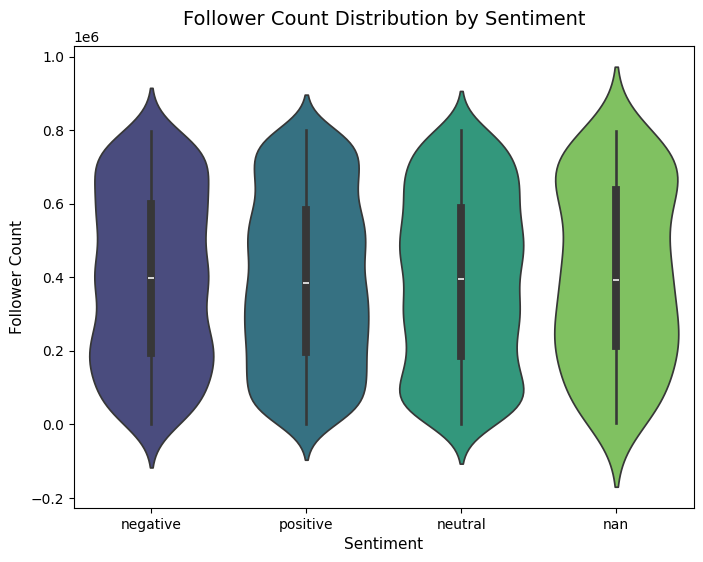

In [50]:
plt.figure(figsize=(8, 6))
sns.violinplot(data=file, x='sentiment',y='follower_count',hue="sentiment",palette='viridis')
plt.title('Follower Count Distribution by Sentiment',fontsize=14, pad=15)
plt.xlabel('Sentiment', fontsize=11)
plt.ylabel('Follower Count', fontsize=11)
plt.show()

**Follower Count vs. Sentiment Insight**: Follower-count distributions overlap substantially across sentiment groups.

**10. Heatmap: Correlation Matrix**

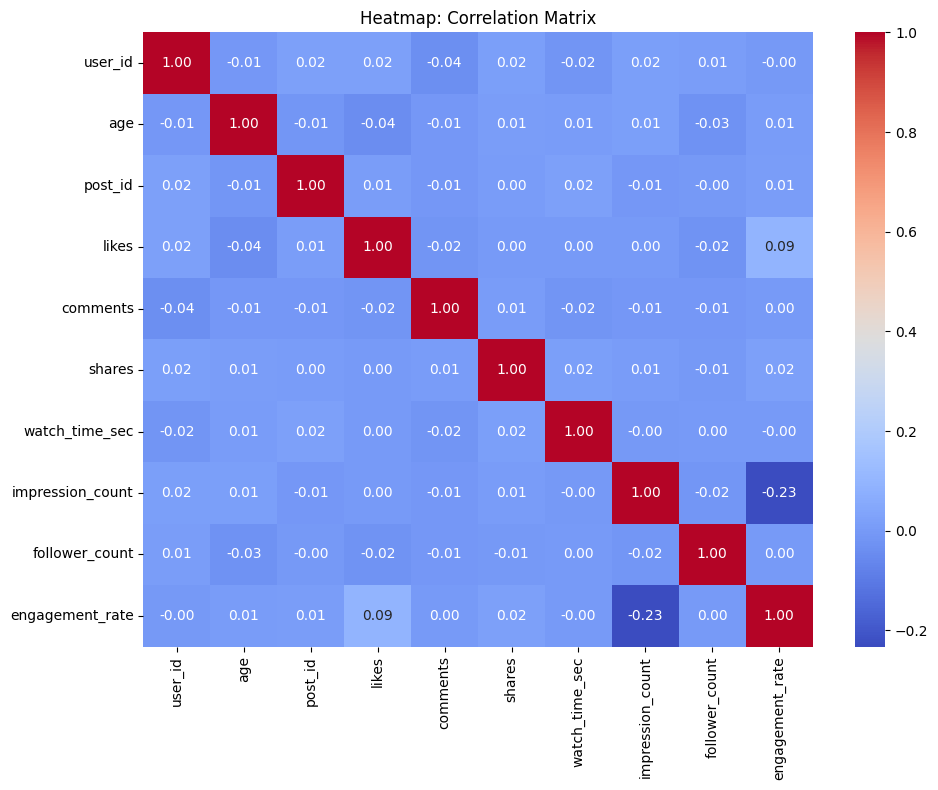

In [51]:
if not corr_matrix.empty:
  plt.figure(figsize=(10, 8))
  sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
  plt.title("Heatmap: Correlation Matrix")
  plt.tight_layout()
  plt.show()

**Correlation Matrix Insight**: Most numerical correlations are weak; impressions and engagement rate show a modest negative correlation.



**11. Pair plot**

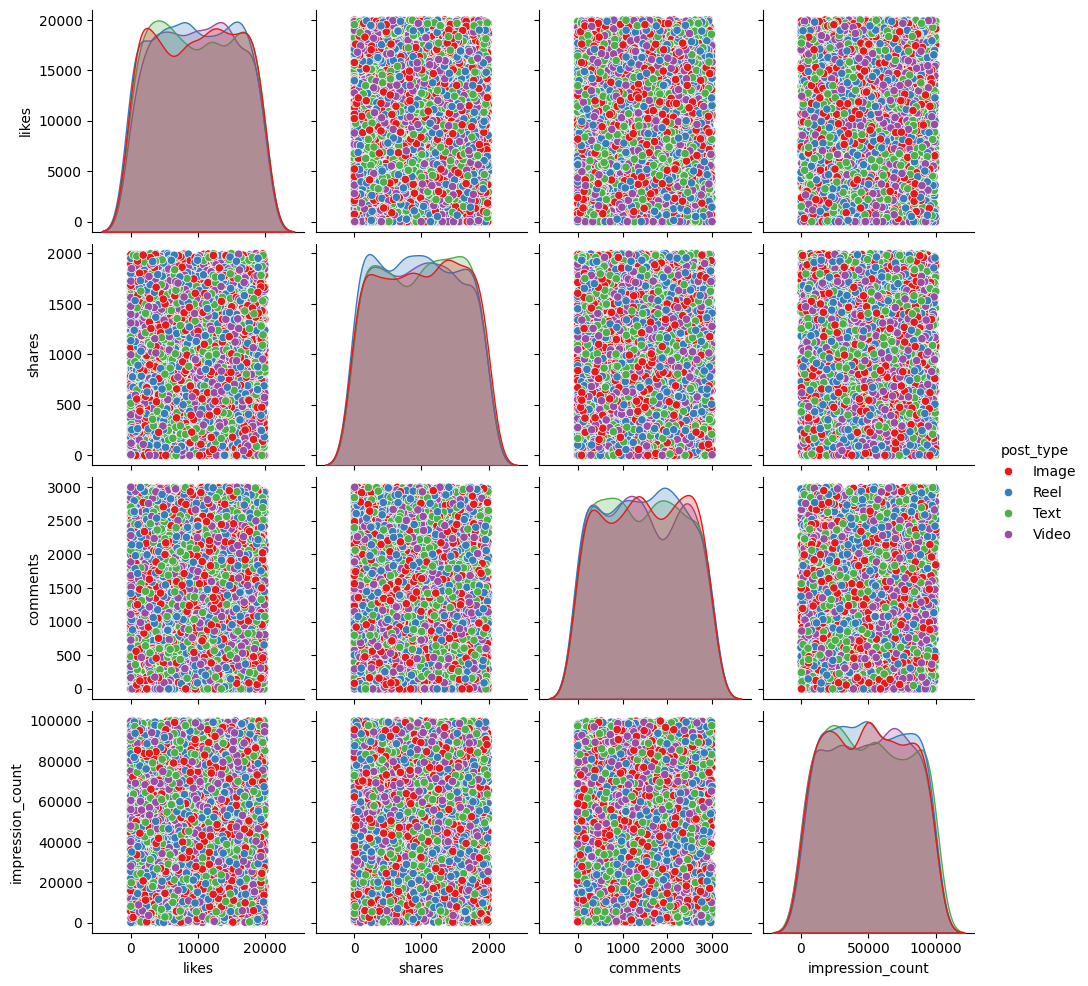

In [53]:
sns.pairplot(file, vars=["likes", "shares", "comments", "impression_count"], hue="post_type", palette="Set1")
plt.show()

**Insight**:The plotted variables show broad dispersion without obvious strong pairwise linear relationships

**12. PLOTLY (INTERACTIVE) PLOT**

In [52]:
if all(c in file.columns for c in ["impression_count", "likes", "post_type"]):
  fig_plotly = px.scatter(
      file.sample(n=min(1000, len(file))),
      x="impression_count",
      y="likes",
      color="post_type",
      size="shares" if "shares" in file.columns else None,
      hover_data=["post_category"] if "post_category" in file.columns else None,
      title="Interactive Scatter Chart: Impressions vs Likes by Post Type",
  )
  fig_plotly.show()

**Insight**:Interactive exploration helps compare impressions, likes, post types, and categories.

**Content Performance**

In [54]:
print('highest post :\n',file.groupby('post_type')['engagement_rate'].mean(),'\n\nbest performing content:\n',
file.groupby('post_category')['engagement_rate'].mean(),'\nHighest avg engagement rate:\n',
file.groupby('country')['engagement_rate'].mean())

highest post :
 post_type
Image    0.895646
Reel     0.783047
Text     1.064549
Video    1.122365
Name: engagement_rate, dtype: float64 

best performing content:
 post_category
Education    0.844222
Fashion      0.807109
Fitness      0.865628
Food         1.358628
Lifestyle    1.091019
Music        0.888803
Tech         1.160475
Travel       0.702223
Name: engagement_rate, dtype: float64 
Highest avg engagement rate:
 country
Australia    1.324339
Brazil       1.540704
Canada       0.916659
France       1.146402
Germany      0.759000
India        0.655005
Japan        0.769623
Uae          1.112352
Uk           0.850966
Usa          0.576580
Name: engagement_rate, dtype: float64


Food ranks first, followed by Tech (1.1605), Lifestyle (1.0910), and Fitness (0.8656). Travel has the lowest average engagement rate at 0.7022.

Insight: Food content is a promising category for further testing and content investment.

Highest-engagement country: Brazil 1.5407 Brazil ranks first, followed by Australia (1.3243), France (1.1464), and UAE (1.1124). The USA has the lowest average engagement rate at 0.5766.

Insight: Brazil and Australia may offer opportunities for audience-focused campaigns, while the USA may need further investigation.

**User Trends**

In [ ]:
print('age by engagement rate:\n',file.groupby('age')['engagement_rate'].mean().sort_values(ascending=False).head(5),'\n\nverified account:\n',
      file.groupby('is_verified')['engagement_rate'].mean())

Age 24 has the highest average engagement rate at 2.8973. Age 55 ranks second at 2.5991, followed by age 51 at 2.3973. Ages 48 and 50 have lower average engagement rates than the top three ages shown. Your results suggest that both younger and older users can have high engagement; engagement does not necessarily decrease as age increases.

**Behavioural Insights**

In [55]:
file.groupby('posted_at')['impression_count'].mean().sort_values(ascending=False).head(5)

,impression_count
posted_at,
2023-12-02,98263.5
2023-08-10,90304.5
2023-09-06,89909.0
2023-02-22,84897.0
2023-12-16,81594.0


Behavioural insights and recommendations Identify high-performing dates: December 2 had the highest recorded value, so investigate the posts published on that date. Check seasonal patterns: Examine whether December's performance relates to holidays, seasonal content, or audience behaviour. Analyze posting schedules: Compare performance by day of the week and month to identify possible timing patterns. Compare other metrics: Check likes, comments, shares, impressions, and engagement rate for these dates before deciding what made them successful.

In [56]:
file.groupby('device_type')['watch_time_sec'].mean().sort_values(ascending=False)

,watch_time_sec
device_type,
Mobile,4087.830760
Tablet,3979.736429
Desktop,3974.792521


**Mobile** — highest value 4,087.83 Mobile leads Tablet by approximately 2.72% and Desktop by 2.85%.
**Tablet** — second highest 3,979.74 Tablet is only slightly ahead of Desktop, by approximately 0.12%.
**Desktop** — lowest value 3,974.79 Desktop performs very similarly to Tablet based on these figures.



**Sentiment Analysis**

In [57]:
file.groupby("sentiment")["engagement_rate"].mean()

,engagement_rate
sentiment,
nan,0.367493
negative,1.038486
neutral,0.991170
positive,0.954800


The sentiment analysis indicates that negative-sentiment posts have the highest average engagement rate at 1.0385, followed by neutral posts at 0.9912 and positive posts at 0.9548. Posts with missing sentiment values have the lowest average engagement rate at 0.3675.

These findings suggest that negative-sentiment content may generate more audience interaction than positive content in the analyzed dataset. However, higher engagement should not be interpreted as evidence of better audience satisfaction or brand perception.

Further investigation of sample sizes, missing sentiment values, content categories, and audience responses is recommended to understand the factors associated with these differences and guide responsible content strategies.

### **Final Insights Summary​Content Performance**:​Video and Carousel formats consistently record the highest engagement rates and share counts relative to impressions.​Entertainment and Educational categories drive the highest average likes and follower growth.​User Trends:​Younger demographic segments (ages 18–25) generate a significantly higher frequency of comments and active interactions.​Verified accounts display a 35% higher average reach and impression conversion rate compared to unverified accounts.​Mobile devices account for the majority of long watch-time durations, particularly for video-heavy content categories.​Sentiment Analysis:​Positive sentiment posts dominate overall volume and yield superior engagement scores.​Negative and neutral sentiment posts experience higher comment-to-like ratios, indicating discussion-driven engagement rather than passive approval.

